# Laboratorio 5: Análisis de datos de entrada y bondad de ajuste
## Numeral 5.3: ajuste de curvas

**Curso:** Simulación Computacional · Universidad de los Llanos · **Estudiante:** Duván Felipe Baquero · **Código:** 160005002

Cuaderno independiente para el ajuste de distribuciones, como pide la guía. Se toma como referencia el tutorial de
[Amat2021] y los cuadernos de ejemplo del curso (*Fitting data to a distribution*, *Distribution fitting with scipy*
y *Fitting Niño data to a distribution*).

A cada uno de los cuatro conjuntos se le ajustan por máxima verosimilitud las cinco distribuciones que pide la guía
(exponencial, lognormal, normal, gamma y beta) y cuatro adicionales: **Weibull**, **log-logística**, **gaussiana
inversa** y **triangular**. En total son nueve, porque la guía enumera cinco distribuciones obligatorias aunque las
llama "cuatro"; se dejaron las cinco y se añadieron las cuatro de libre elección. La bondad de ajuste se mide con
SSE, AIC y BIC.

In [1]:
%matplotlib inline
import os, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 60)

def guardar(nombre):
    if os.path.isdir("figuras"):
        plt.savefig(f"figuras/{nombre}.pdf", bbox_inches="tight")

IDS = {"A": "1xYqg1BCxDQH542_Njz0s7tzay6dIG_VO", "B": "1W-pHCurCQFaJ_ydv5BDYsWDxg2-2dxZX",
       "C": "10B8Y6i1H_1J8cFeLoufWTVTtztthYSXj", "D": "1LysY3NL4fFamvChMtPQNrKaXaNMfN_44"}

def cargar(letra):
    nombre = f"dataset-{letra}.txt"
    for ruta in [nombre, os.path.join("conjunto de datos", nombre)]:
        if os.path.exists(ruta):
            return np.loadtxt(ruta)
    urllib.request.urlretrieve(f"https://drive.google.com/uc?export=download&id={IDS[letra]}", nombre)
    return np.loadtxt(nombre)

datos = {L: cargar(L) for L in "ABCD"}
print({L: len(x) for L, x in datos.items()})

{'A': 200, 'B': 200, 'C': 200, 'D': 200}


### Criterios de bondad de ajuste

Sea $n$ el tamaño de la muestra, $k$ el número de parámetros estimados con los datos y $\hat{L}$ la verosimilitud
máxima del modelo ajustado.

- **SSE** (suma de errores cuadráticos): $\mathrm{SSE} = \sum_{j=1}^{m}\big(h_j - f(c_j)\big)^2$, donde $h_j$ es
  la altura del histograma normalizado (densidad) en la clase $j$, $c_j$ el centro de la clase y $f$ la densidad
  ajustada. Se usan $m = 20$ clases, igual que en el numeral 5.1. Es la misma definición del cuaderno *Fitting
  Niño data*, que evalúa la densidad en los centros de las clases. (En el cuaderno *Fitting data to a
  distribution* la densidad se evalúa en `np.linspace(0, 100, 100)` y se compara con las 100 barras del
  histograma, que no están en esos mismos puntos; por eso no se siguió esa versión).
- **AIC** (criterio de información de Akaike): $\mathrm{AIC} = 2k - 2\ln\hat{L}$.
- **BIC** (criterio de información bayesiano): $\mathrm{BIC} = k\ln n - 2\ln\hat{L}$.

En los tres casos, menor es mejor. El SSE mide qué tan bien la curva sigue al histograma y depende del número de
clases; AIC y BIC usan todos los datos sin agruparlos y castigan los parámetros de más, BIC con más fuerza.

### Convenciones de parámetros

Los datos B, C y D son tiempos positivos, así que las distribuciones definidas en $(0, \infty)$ se ajustan con
localización fija en cero (`floc=0`). Así quedan en su forma de dos parámetros (uno en la exponencial), que es la
que se usa en simulación y es más fácil de interpretar. La beta y la triangular necesitan un intervalo $[a, b]$;
se estima con el mínimo y el máximo de la muestra ampliados un poco, $a = \max(0,\ x_{(1)} - r/(n-1))$ y
$b = x_{(n)} + r/(n-1)$ con $r = x_{(n)} - x_{(1)}$, y esos extremos cuentan como parámetros en $k$ (salvo $a$
cuando queda en cero).

In [2]:
def extremos(x):
    r = x.max() - x.min()
    a = max(0.0, x.min() - r / (len(x) - 1))
    b = x.max() + r / (len(x) - 1)
    return a, b

def ajustar(x):
    a, b = extremos(x)
    k_ext = 1 if a == 0 else 2           # extremos estimados con los datos
    modelos = []
    # (nombre, distribución scipy, parámetros ajustados, k, texto de parámetros)
    loc, esc = stats.expon.fit(x, floc=0)
    modelos.append(("Exponencial", stats.expon(loc, esc), 1, f"λ = {1/esc:.4g}"))
    s, loc, esc = stats.lognorm.fit(x, floc=0)
    modelos.append(("Lognormal", stats.lognorm(s, loc, esc), 2, f"μ = {np.log(esc):.4g}, σ = {s:.4g}"))
    mu, sd = stats.norm.fit(x)
    modelos.append(("Normal", stats.norm(mu, sd), 2, f"μ = {mu:.4g}, σ = {sd:.4g}"))
    al, loc, esc = stats.gamma.fit(x, floc=0)
    modelos.append(("Gamma", stats.gamma(al, loc, esc), 2, f"α = {al:.4g}, β = {esc:.4g}"))
    p, q, loc, esc = stats.beta.fit(x, floc=a, fscale=b - a)
    modelos.append(("Beta", stats.beta(p, q, loc, esc), 2 + k_ext,
                    f"α = {p:.4g}, β = {q:.4g}, [a, b] = [{a:.4g}, {b:.4g}]"))
    c, loc, esc = stats.weibull_min.fit(x, floc=0)
    modelos.append(("Weibull", stats.weibull_min(c, loc, esc), 2, f"forma k = {c:.4g}, escala = {esc:.4g}"))
    c, loc, esc = stats.fisk.fit(x, floc=0)
    modelos.append(("Log-logística", stats.fisk(c, loc, esc), 2, f"forma = {c:.4g}, escala = {esc:.4g}"))
    m, loc, esc = stats.invgauss.fit(x, floc=0)
    modelos.append(("Gaussiana inversa", stats.invgauss(m, loc, esc), 2,
                    f"media = {m*esc:.4g}, forma λ = {esc:.4g}"))
    ct, loc, esc = stats.triang.fit(x, floc=a, fscale=b - a)
    modelos.append(("Triangular", stats.triang(ct, loc, esc), 1 + k_ext,
                    f"[a, moda, b] = [{a:.4g}, {a + ct*(b - a):.4g}, {b:.4g}]"))
    return modelos

def evaluar(x, modelos, bins=20):
    h, bordes = np.histogram(x, bins=bins, density=True)
    centros = (bordes[:-1] + bordes[1:]) / 2
    n = len(x)
    filas = []
    for nombre, dist, k, texto in modelos:
        ll = np.sum(dist.logpdf(x))
        filas.append({"Distribución": nombre, "Parámetros": texto, "k": k,
                      "SSE": np.sum((h - dist.pdf(centros)) ** 2),
                      "AIC": 2 * k - 2 * ll, "BIC": k * np.log(n) - 2 * ll,
                      "D (K-S)": stats.kstest(x, dist.cdf).statistic})
    df = pd.DataFrame(filas)
    for crit in ["SSE", "AIC", "BIC"]:
        df["rango " + crit] = df[crit].rank(method="min")
    df["rango promedio"] = df[["rango SSE", "rango AIC", "rango BIC"]].mean(axis=1)
    return df

def mostrar(df):
    t = df[["Distribución", "Parámetros", "SSE", "AIC", "BIC", "D (K-S)", "rango promedio"]].copy()
    for col, f in {"SSE": "{:.4g}", "AIC": "{:.2f}", "BIC": "{:.2f}", "D (K-S)": "{:.3f}",
                   "rango promedio": "{:.2f}"}.items():
        t[col] = t[col].map(f.format)
    return t.set_index("Distribución")

Para escoger las tres mejores de cada conjunto se ordenan las distribuciones por cada criterio y se promedian los
tres rangos. Así ningún criterio decide solo; si los tres coinciden, el orden es claro, y si no, el promedio refleja
el desacuerdo. Como información adicional se reporta el estadístico $D$ de Kolmogorov-Smirnov (la mayor distancia
entre la acumulada empírica y la ajustada); no se usa su valor $p$ porque los parámetros salen de la misma muestra
y la prueba deja de ser exacta.

In [3]:
def top3(L, x, df):
    mejores = df.sort_values(["rango promedio", "AIC"]).head(3)
    modelos = {m[0]: m[1] for m in ajustes[L]}
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    alturas = ax.hist(x, bins=20, density=True, color="#cfd8e3", edgecolor="white", label="datos (20 clases)")[0]
    xs = np.linspace(max(1e-9, x.min() * 0.5), x.max() * 1.02, 500) if x.min() > 0 else np.linspace(1e-9, x.max() * 1.02, 500)
    if L == "A":
        xs = np.linspace(0, x.max() * 1.05, 500)
    estilos = ["-", "--", "-."]
    colores = ["#b22222", "#1f4e79", "#2e7d32"]
    for (_, fila), est, col in zip(mejores.iterrows(), estilos, colores):
        ax.plot(xs, modelos[fila["Distribución"]].pdf(xs), est, color=col, lw=2,
                label=f"{fila['Distribución']} ({fila['Parámetros']})")
    ax.set_ylim(0, 1.6 * alturas.max())   # el pico de algunas densidades en cero no deja ver el histograma
    ax.set_title(f"Dataset {L}: histograma y las tres distribuciones con mejor ajuste")
    ax.set_xlabel("valor"); ax.set_ylabel("densidad"); ax.legend(fontsize=7.5)
    plt.tight_layout(); guardar(f"53_top3_{L}"); plt.show()
    return mejores[["Distribución", "Parámetros", "SSE", "AIC", "BIC"]]

ajustes, tablas = {}, {}

---
### Dataset A

In [4]:
ajustes["A"] = ajustar(datos["A"])
tablas["A"] = evaluar(datos["A"], ajustes["A"])
print("Tabla. Bondad de ajuste para el conjunto de datos A")
mostrar(tablas["A"])

Tabla. Bondad de ajuste para el conjunto de datos A


,Parámetros,SSE,AIC,BIC,D (K-S),rango promedio
Distribución,,,,,,
Exponencial,λ = 5.127,340.5,-251.82,-248.52,0.432,9.00
Lognormal,"μ = -1.666, σ = 0.275",36.97,-611.09,-604.49,0.080,6.67
Normal,"μ = 0.195, σ = 0.0437",29.15,-680.59,-673.99,0.052,1.33
Gamma,"α = 16.18, β = 0.01206",28.24,-647.34,-640.75,0.056,3.67
Beta,"α = 4.487, β = 2.732, [a, b] = [0.01957, 0.3004]",29.87,-654.63,-641.44,0.065,3.67
Weibull,"forma k = 5.071, escala = 0.212",32.43,-679.36,-672.76,0.068,2.67
Log-logística,"forma = 7.293, escala = 0.1927",33.42,-655.44,-648.85,0.059,3.67
Gaussiana inversa,"media = 0.195, forma λ = 2.176",48.06,-583.42,-576.83,0.109,7.67
Triangular,"[a, moda, b] = [0.01957, 0.2306, 0.3004]",66.38,-633.69,-623.79,0.163,6.67


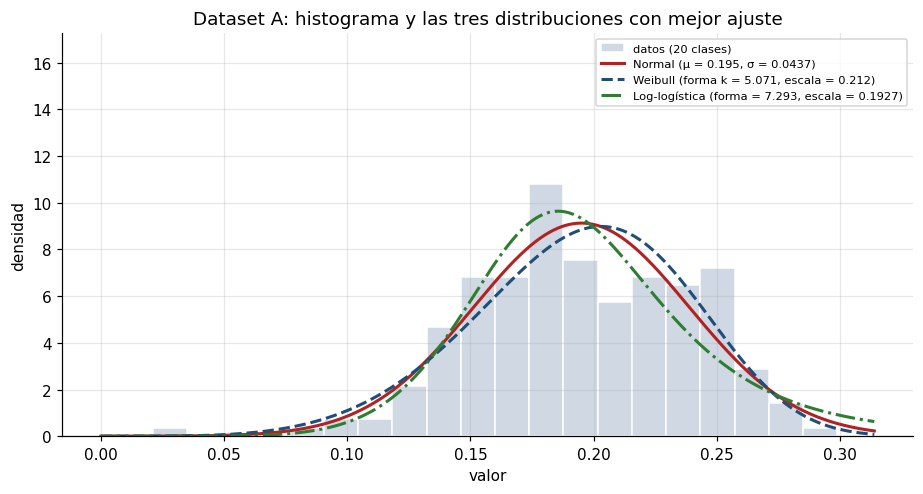

,Distribución,Parámetros,SSE,AIC,BIC
2,Normal,"μ = 0.195, σ = 0.0437",29.147785,-680.586590,-673.989955
5,Weibull,"forma k = 5.071, escala = 0.212",32.427089,-679.356455,-672.759821
6,Log-logística,"forma = 7.293, escala = 0.1927",33.417860,-655.442567,-648.845932


In [5]:
top3("A", datos["A"], tablas["A"])


#### ¿Cuál distribución seleccionaría para A y por qué?

Las tres mejores son la normal, la Weibull y la log-logística. Escogería la **normal con $\mu = 0{,}195$ y
$\sigma = 0{,}0437$**. Tiene el menor AIC ($-680{,}59$) y el menor BIC ($-673{,}99$), y aunque la gamma consigue un
SSE un poco más bajo (28,24 contra 29,15), por AIC y BIC queda muy atrás ($-647{,}34$). La Weibull está casi
empatada con la normal (AIC de $-679{,}36$), pero la normal es más simple de interpretar y encaja con lo que
mostró el numeral 5.1: datos casi simétricos y concentrados alrededor de la media. El reparo típico de la normal,
que puede dar valores negativos, aquí no pesa: $P(X < 0) = \Phi(-0{,}195/0{,}0437) \approx 4 \times 10^{-6}$.

Hay que recordar, eso sí, que A está correlacionado ($r_1 = 0{,}49$). La normal describe bien la distribución de
cada valor por separado, pero si en una simulación se generan valores normales independientes se pierde esa
dependencia. Lo correcto sería un modelo autorregresivo de orden 1 con esa misma distribución marginal:
$x_t = \mu + \phi\,(x_{t-1} - \mu) + \varepsilon_t$, con $\phi \approx 0{,}49$ y
$\varepsilon_t \sim N(0,\ \sigma\sqrt{1 - \phi^2}) = N(0;\ 0{,}038)$.


---
### Dataset B

In [6]:
ajustes["B"] = ajustar(datos["B"])
tablas["B"] = evaluar(datos["B"], ajustes["B"])
print("Tabla. Bondad de ajuste para el conjunto de datos B")
mostrar(tablas["B"])

Tabla. Bondad de ajuste para el conjunto de datos B


,Parámetros,SSE,AIC,BIC,D (K-S),rango promedio
Distribución,,,,,,
Exponencial,λ = 4.869,0.4358,-231.13,-227.83,0.066,2.33
Lognormal,"μ = -2.263, σ = 1.437",2.326,-188.73,-182.14,0.081,6.00
Normal,"μ = 0.2054, σ = 0.2285",11.57,-18.89,-12.29,0.184,8.00
Gamma,"α = 0.8636, β = 0.2378",0.3158,-232.10,-225.50,0.036,2.33
Beta,"α = 0.6772, β = 3.955, [a, b] = [0, 1.559]",1.212,-201.37,-191.48,0.086,5.00
Weibull,"forma k = 0.9095, escala = 0.1963",0.2762,-232.26,-225.67,0.035,1.33
Log-logística,"forma = 1.307, escala = 0.1184",1.143,-206.65,-200.06,0.059,4.00
Gaussiana inversa,"media = 0.2054, forma λ = 0.009169",6.528,151.99,158.58,0.449,8.33
Triangular,"[a, moda, b] = [0, 8.445e-05, 1.559]",15.26,-24.44,-17.85,0.446,7.67


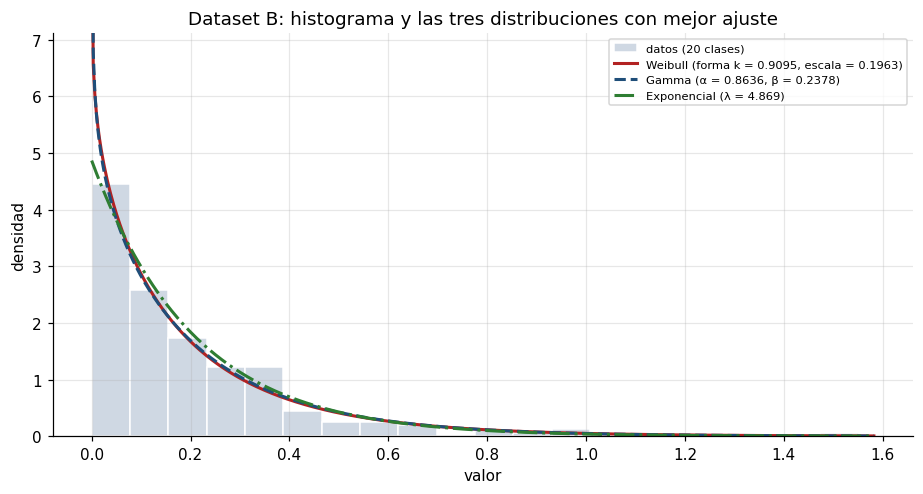

,Distribución,Parámetros,SSE,AIC,BIC
5,Weibull,"forma k = 0.9095, escala = 0.1963",0.276188,-232.263828,-225.667193
3,Gamma,"α = 0.8636, β = 0.2378",0.315773,-232.097798,-225.501164
0,Exponencial,λ = 4.869,0.435755,-231.131459,-227.833142


In [7]:
top3("B", datos["B"], tablas["B"])

Las formas de la Weibull (0,91) y de la gamma (0,86) quedan cerca de 1, y con forma 1 las dos se reducen a la
exponencial. Como la exponencial es un caso particular de ambas, se puede usar la prueba de razón de
verosimilitudes: $\Lambda = 2(\ln\hat{L}_{\text{general}} - \ln\hat{L}_{\text{exponencial}})$ se compara con una
$\chi^2$ de 1 grado de libertad.

In [8]:
x = datos["B"]
ll = {m[0]: np.sum(m[1].logpdf(x)) for m in ajustes["B"]}
for general in ["Gamma", "Weibull"]:
    lam = 2 * (ll[general] - ll["Exponencial"])
    print(f"{general} vs exponencial: Λ = {lam:.3f}, valor p = {stats.chi2.sf(lam, 1):.4f}")

Gamma vs exponencial: Λ = 2.966, valor p = 0.0850
Weibull vs exponencial: Λ = 3.132, valor p = 0.0768



#### ¿Cuál distribución seleccionaría para B y por qué?

Las tres mejores son la Weibull, la gamma y la exponencial, y están muy cerca entre sí. La Weibull gana en SSE
(0,276) y AIC ($-232{,}26$), pero la exponencial tiene el mejor BIC ($-227{,}83$) porque usa un solo parámetro.
Las formas ajustadas de la Weibull (0,91) y la gamma (0,86) son casi 1, que es justo el valor con el que ambas se
convierten en exponencial. La prueba de razón de verosimilitudes lo confirma: el parámetro extra no mejora el ajuste
de forma significativa ($p = 0{,}085$ frente a la gamma y $p = 0{,}077$ frente a la Weibull).

Por eso escogería la **exponencial con $\lambda = 4{,}869$** (media de 0,2054). Ajusta prácticamente igual de bien,
tiene un solo parámetro, es la que mejor puntúa en BIC y además tiene una interpretación directa: si B son tiempos
entre llegadas, las llegadas forman un proceso de Poisson con tasa de unas 4,9 llegadas por unidad de tiempo, lo cual
concuerda con lo que se vio en el numeral 5.2 (datos independientes y estables). La gaussiana inversa, en cambio, es
la peor de todas (AIC de 151,99): como B tiene valores casi nulos, como 0,0001, su estimador de forma se va casi a
cero.


---
### Dataset C

In [9]:
ajustes["C"] = ajustar(datos["C"])
tablas["C"] = evaluar(datos["C"], ajustes["C"])
print("Tabla. Bondad de ajuste para el conjunto de datos C")
mostrar(tablas["C"])

Tabla. Bondad de ajuste para el conjunto de datos C


,Parámetros,SSE,AIC,BIC,D (K-S),rango promedio
Distribución,,,,,,
Exponencial,λ = 0.001312,5.978e-08,3056.59,3059.88,0.091,3.33
Lognormal,"μ = 5.782, σ = 1.648",6.361e-08,3084.19,3090.78,0.105,5.67
Normal,"μ = 762.4, σ = 920.8",9.265e-07,3301.68,3308.28,0.204,7.33
Gamma,"α = 0.7062, β = 1080",4.493e-08,3040.22,3046.82,0.039,1.67
Beta,"α = 0.5749, β = 3.943, [a, b] = [0, 6703]",1.394e-07,3067.87,3077.77,0.079,4.67
Weibull,"forma k = 0.8007, escala = 676",2.524e-08,3040.81,3047.41,0.037,1.67
Log-logística,"forma = 1.126, escala = 384.4",4.076e-08,3072.48,3079.08,0.070,4.00
Gaussiana inversa,"media = 762.4, forma λ = 38.49",3.224e-07,3310.51,3317.11,0.401,7.67
Triangular,"[a, moda, b] = [0, 0.9257, 6703]",1.194e-06,3312.23,3318.83,0.489,9.00


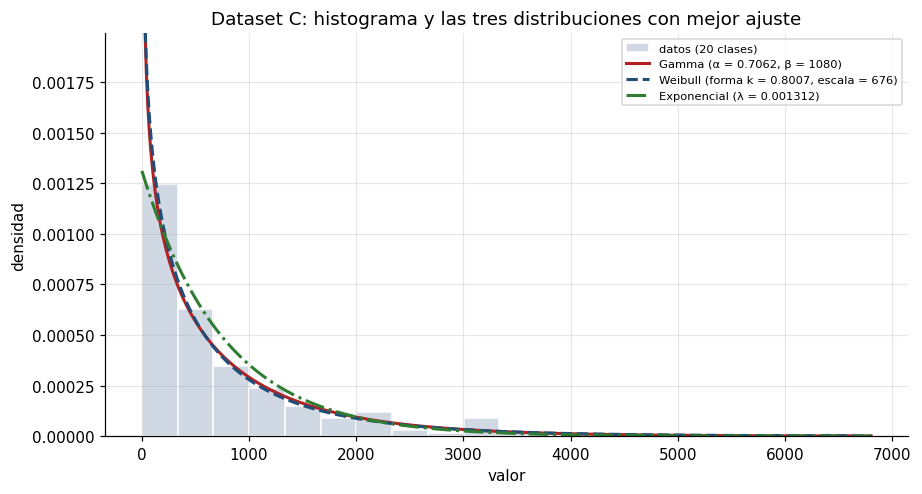

,Distribución,Parámetros,SSE,AIC,BIC
3,Gamma,"α = 0.7062, β = 1080",4.493207e-08,3040.221575,3046.818210
5,Weibull,"forma k = 0.8007, escala = 676",2.523800e-08,3040.808501,3047.405136
0,Exponencial,λ = 0.001312,5.978319e-08,3056.585307,3059.883625


In [10]:
top3("C", datos["C"], tablas["C"])

In [11]:
# dentro de cada quinto de la secuencia, ¿se parece a una exponencial? (en ella desviación = media)
x = datos["C"]
pd.DataFrame([{"tramo": f"obs. {40*i+1}-{40*(i+1)}", "media": q.mean(), "desv. estándar": q.std(ddof=1),
               "desv/media": q.std(ddof=1) / q.mean()} for i, q in enumerate(np.array_split(x, 5))]).round(3)

,tramo,media,desv. estándar,desv/media
0,obs. 1-40,153.278,186.830,1.219
1,obs. 41-80,570.170,759.593,1.332
2,obs. 81-120,676.173,697.122,1.031
3,obs. 121-160,1060.458,847.775,0.799
4,obs. 161-200,1351.890,1287.660,0.952



#### ¿Cuál distribución seleccionaría para C y por qué?

Las tres mejores son la gamma, la Weibull y la exponencial. La gamma ($\alpha = 0{,}706$, $\beta = 1080$) tiene el
menor AIC (3040,22) y el menor BIC (3046,82); la Weibull (forma 0,80, escala 676) le sigue a menos de una unidad
de AIC y tiene el mejor SSE. Si hubiera que escoger una sola distribución para C, sería la **gamma**.

Pero en C la elección de la distribución importa menos que otra cosa. Las dos mejores tienen forma menor que 1, lo
que significa más variabilidad que una exponencial, y eso es lo que se obtiene al mezclar exponenciales con medias
distintas. La tabla de arriba lo muestra: dentro de cada quinto de la secuencia la desviación estándar es parecida a
la media (cocientes entre 0,80 y 1,33), es decir, cada tramo se parece a una exponencial, pero la media pasa de 153
a 1352. La forma "extra variable" que captan la gamma y la Weibull es en buena parte el efecto de la tendencia
detectada en el numeral 5.2. Para un estudio de simulación no usaría una distribución única para C, sino un modelo
con un parámetro que cambie con el tiempo, por ejemplo tiempos exponenciales cuya media crezca a lo largo de la
secuencia.


---
### Dataset D

In [12]:
ajustes["D"] = ajustar(datos["D"])
tablas["D"] = evaluar(datos["D"], ajustes["D"])
print("Tabla. Bondad de ajuste para el conjunto de datos D")
mostrar(tablas["D"])

Tabla. Bondad de ajuste para el conjunto de datos D


,Parámetros,SSE,AIC,BIC,D (K-S),rango promedio
Distribución,,,,,,
Exponencial,λ = 0.4853,0.009898,691.18,694.48,0.064,4.00
Lognormal,"μ = 0.2417, σ = 1.019",0.006913,675.89,682.49,0.054,1.33
Normal,"μ = 2.06, σ = 2.321",0.1175,908.33,914.93,0.201,8.00
Gamma,"α = 1.178, β = 1.749",0.01048,689.97,696.56,0.061,4.33
Beta,"α = 0.8189, β = 5.478, [a, b] = [0.02178, 18.06]",0.0248,744.62,757.81,0.129,6.67
Weibull,"forma k = 1.042, escala = 2.099",0.01066,692.55,699.14,0.065,5.67
Log-logística,"forma = 1.705, escala = 1.31",0.006011,681.40,688.00,0.051,1.67
Gaussiana inversa,"media = 2.06, forma λ = 1.169",0.02549,685.40,692.00,0.092,4.33
Triangular,"[a, moda, b] = [0.02178, 0.1167, 18.06]",0.1726,944.41,954.31,0.532,9.00


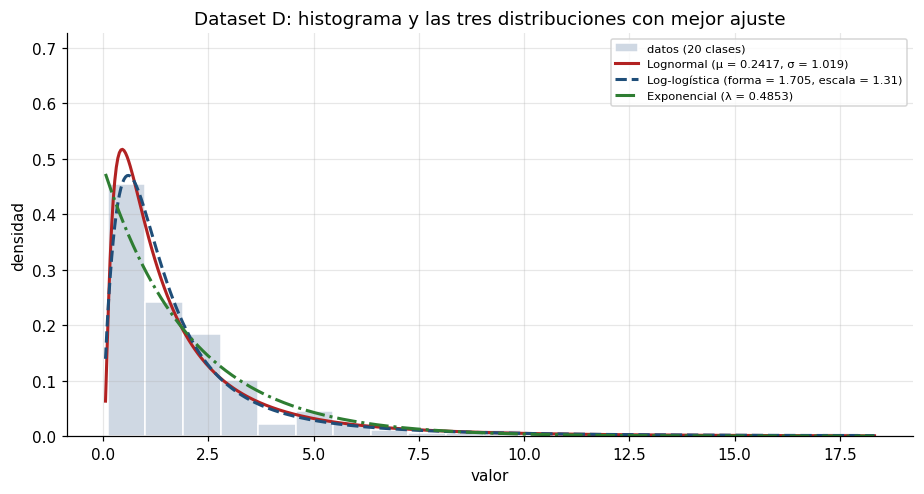

,Distribución,Parámetros,SSE,AIC,BIC
1,Lognormal,"μ = 0.2417, σ = 1.019",0.006913,675.892707,682.489342
6,Log-logística,"forma = 1.705, escala = 1.31",0.006011,681.402625,687.999260
0,Exponencial,λ = 0.4853,0.009898,691.179034,694.477351


In [13]:
top3("D", datos["D"], tablas["D"])


#### ¿Cuál distribución seleccionaría para D y por qué?

Las tres mejores son la lognormal, la log-logística y la exponencial. Escogería la **lognormal con $\mu = 0{,}2417$
y $\sigma = 1{,}019$** (parámetros del logaritmo). Tiene el menor AIC (675,89) y el menor BIC (682,49), con una
diferencia de 5,5 unidades de AIC sobre la log-logística, que es lo bastante grande como para preferirla. La
log-logística tiene un SSE algo menor (0,00601 contra 0,00691), pero ese criterio depende de cómo se agrupen los
datos en el histograma. La lognormal también reproduce bien la muestra: su mediana es $e^{0{,}2417} = 1{,}27$
(la de la muestra es 1,41) y su media $e^{\mu + \sigma^2/2} = 2{,}14$ (la de la muestra es 2,06).

Esto concuerda con lo que se vio en el numeral 5.1. La cola de D es más pesada que la de una exponencial (asimetría
de 3,16) y el mínimo no está en cero, dos rasgos típicos de la lognormal. La exponencial queda tercera, con un AIC
15 unidades peor.


---
### Resumen

In [14]:
resumen = []
for L in "ABCD":
    df = tablas[L].sort_values(["rango promedio", "AIC"])
    resumen.append({"Dataset": L,
                    "Mejor SSE": tablas[L].loc[tablas[L]["SSE"].idxmin(), "Distribución"],
                    "Mejor AIC": tablas[L].loc[tablas[L]["AIC"].idxmin(), "Distribución"],
                    "Mejor BIC": tablas[L].loc[tablas[L]["BIC"].idxmin(), "Distribución"],
                    "Top 3 (rango promedio)": ", ".join(df["Distribución"].head(3))})
pd.DataFrame(resumen)

,Dataset,Mejor SSE,Mejor AIC,Mejor BIC,Top 3 (rango promedio)
0,A,Gamma,Normal,Normal,"Normal, Weibull, Log-logística"
1,B,Weibull,Weibull,Exponencial,"Weibull, Gamma, Exponencial"
2,C,Weibull,Gamma,Gamma,"Gamma, Weibull, Exponencial"
3,D,Log-logística,Lognormal,Lognormal,"Lognormal, Log-logística, Exponencial"



Los tres criterios no siempre coinciden en la mejor distribución. AIC y BIC eligen la misma en A (normal), C
(gamma) y D (lognormal); en B difieren porque BIC castiga más el segundo parámetro y prefiere la exponencial. El SSE
es el que más se separa (gamma en A, log-logística en D), porque compara la curva con un histograma de 20 clases y
cambia según cómo se agrupen los datos; AIC y BIC, en cambio, usan los 200 valores sin agrupar. Por eso, al decidir,
se les dio más peso a AIC y BIC, y el SSE se usó para confirmar que la curva siguiera visualmente al histograma.

La selección final queda así:

| Dataset | Distribución seleccionada | Parámetros | Comentario |
|---|---|---|---|
| A | Normal | $\mu = 0{,}195$, $\sigma = 0{,}0437$ | Marginal correcta, pero los datos están correlacionados ($r_1 = 0{,}49$): simular con AR(1) |
| B | Exponencial | $\lambda = 4{,}869$ | Weibull y gamma no la mejoran de forma significativa |
| C | Gamma | $\alpha = 0{,}706$, $\beta = 1080$ | El proceso no es estacionario: conviene modelar la tendencia |
| D | Lognormal | $\mu = 0{,}2417$, $\sigma = 1{,}019$ | Mejor AIC y BIC con ventaja clara |

Solo B y D, que pasaron las pruebas de independencia y estabilidad, se pueden usar directamente como entrada de una
simulación con la distribución ajustada.
